# Surface meshes from CAD

`mesh_cad_surface` triangulates the faces of a CAD model into one conforming surface mesh at a target edge size `h`, with no CAD kernel. The model is the B-rep a Kratos CAD JSON read keeps in `mesh.info["brep"]`, or a STEP or IGES read through OpenCASCADE.

- **Conforming.** Every B-rep edge is sampled once, by arc length, and its points are shared by every face that uses it, so the faces meet exactly and a closed solid comes out watertight.
- **Per face.** Each face is a constrained Delaunay triangulation of its parameter domain, mapped so that the triangulation follows the surface's own metric on average, filled with an equilateral lattice of step `h`, and lifted onto the surface. Every orientation and in-circle decision is one of Shewchuk's exact predicates.
- **Honest.** A face that cannot be meshed is left out and reported by index and reason, never meshed wrong; the report counts the open, non-manifold and misoriented edges, so a hole is always visible.
- **Deterministic.** The output is identical across parallel backends and thread counts.
- **Quality on request.** `min_angle` refines every face until its triangles' smallest angles on the surface reach the bound, and `smooth_iterations` smooths the inside under a guard (v17.15.0).

It is also a CLI verb and an MCP tool: `meshioplusplus mesh-cad-surface part.cad.json part.vtu --size 0.1`. See `doc/mesh_cad.md`.

In [1]:
import os
import pathlib
import tempfile

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import meshioplusplus as mp

try:
    import pyvista as pv
    pv.OFF_SCREEN = True
    pv.set_jupyter_backend('static')
    from vtkmodules.vtkCommonCore import vtkLogger
    vtkLogger.SetStderrVerbosity(vtkLogger.VERBOSITY_OFF)  # no X server: expected
except Exception:  # pragma: no cover - PyVista is optional
    pv = None

REPO = pathlib.Path(os.getcwd()).parent.parent
CAD = REPO / 'tests' / 'python' / 'meshes' / 'cad_json'
DOC_IMAGES = REPO / 'doc' / 'public' / 'images'


def save_img(name, img=None):
    """Write a render (or the current matplotlib figure) to doc/public/images/<name>.png."""
    try:
        os.makedirs(DOC_IMAGES, exist_ok=True)
        path = DOC_IMAGES / (name + '.png')
        if img is None:
            plt.savefig(path, dpi=110, bbox_inches='tight')
        else:
            plt.imsave(path, img)
    except Exception as exc:  # pragma: no cover - read-only checkout
        print('doc image not written:', exc)


def gl_available():
    """Probe off-screen GL in a child process: a missing GL stack can kill the
    interpreter outright, which no try/except in this one would survive."""
    if pv is None:
        return False
    import subprocess, sys
    probe = ('import pyvista as pv; pv.OFF_SCREEN = True; pl = pv.Plotter(off_screen=True); '
             'pl.add_mesh(pv.Sphere()); pl.screenshot(return_img=True)')
    try:
        return subprocess.run([sys.executable, '-c', probe], capture_output=True,
                              timeout=120).returncode == 0
    except Exception:
        return False


GL = gl_available()
print('PyVista rendering' if GL else 'matplotlib fallback (no off-screen GL)')


def to_pyvista(mesh):
    with tempfile.NamedTemporaryFile(suffix='.vtu', delete=False) as f:
        tmp = f.name
    try:
        mp.write(tmp, mesh)
        return pv.read(tmp)
    finally:
        os.unlink(tmp)


def triangles(mesh):
    return np.asarray([c for c in mesh.cells if c.type == 'triangle'][0].data)


def render(meshes, titles, save, view=(25, 35), cmap='tab20'):
    """Surface meshes side by side, coloured by their source face (cad:face):
    PyVista when GL is available, else matplotlib 3-D collections."""
    n = len(meshes)
    if GL:
        pl = pv.Plotter(off_screen=True, shape=(1, n), window_size=(420 * n, 420), border=False)
        for k, (m, title) in enumerate(zip(meshes, titles)):
            pl.subplot(0, k)
            grid = to_pyvista(m).extract_cells_by_type(pv.CellType.TRIANGLE)
            pl.add_mesh(grid, scalars='cad:face', cmap=cmap, clim=(0, 19), show_edges=True,
                        edge_color='#222222', line_width=0.4, show_scalar_bar=False,
                        ambient=0.35, diffuse=0.65)
            pl.add_text(title, font_size=9)
            pl.camera.elevation, pl.camera.azimuth = view
            pl.reset_camera()
        img = pl.screenshot(return_img=True)
        pl.close()
        save_img(save, img)
        plt.figure(figsize=(4.2 * n, 4.2)); plt.imshow(img); plt.axis('off'); plt.show()
        return
    fig = plt.figure(figsize=(4.2 * n, 4.2))
    for k, (m, title) in enumerate(zip(meshes, titles)):
        ax = fig.add_subplot(1, n, k + 1, projection='3d')
        p, t = np.asarray(m.points), triangles(m)
        face = np.asarray(m.cell_data['cad:face'][0], dtype=float)
        colours = plt.get_cmap(cmap)((face % 20) / 19.0)
        ax.add_collection3d(Poly3DCollection(p[t], facecolors=colours, edgecolors='k', linewidths=0.15))
        lo, hi = p.min(axis=0), p.max(axis=0)
        ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
        ax.set_box_aspect(hi - lo + 1e-9); ax.view_init(elev=view[0], azim=view[1])
        ax.set_axis_off(); ax.set_title(title, fontsize=9)
    save_img(save)
    plt.show()


def measure(mesh):
    """Area and enclosed volume (divergence theorem) of the triangles."""
    p, t = np.asarray(mesh.points), triangles(mesh)
    a, b, c = p[t[:, 0]], p[t[:, 1]], p[t[:, 2]]
    area = 0.5 * np.linalg.norm(np.cross(b - a, c - a), axis=1).sum()
    return area, np.einsum('ij,ij->i', a, np.cross(b, c)).sum() / 6.0


def show_report(report, keys):
    for k in keys:
        v = report[k]
        print(f'{k:24s} {v:.4g}' if isinstance(v, float) else f'{k:24s} {v}')
    for w in report['warnings']:
        print('warning:', w)

PyVista rendering


## Closed solids come out watertight

Three closed solids from the CAD JSON fixtures: a unit cube (six planar faces), a capped cylinder (its side is one periodic face cut open along a seam, which the edge sampler shares between the face's two sides) and a sphere (two hemispheres, each with two poles). The report's `num_open_edges`, `num_non_manifold_edges` and `num_misoriented_edges` are all zero: every triangle edge is used exactly twice, in opposite directions.

unit_cube:
num_faces                6
num_failed               0
num_points               194
num_triangles            384
num_open_edges           0
num_non_manifold_edges   0
num_misoriented_edges    0
min_angle_deg            23.79
max_edge                 0.2479
capped_cylinder:
num_faces                3
num_failed               0
num_points               600
num_triangles            1196
num_open_edges           0
num_non_manifold_edges   0
num_misoriented_edges    0
min_angle_deg            25.25
max_edge                 0.2813
sphere:
num_faces                2
num_failed               0
num_points               673
num_triangles            1342
num_open_edges           0
num_non_manifold_edges   0
num_misoriented_edges    0
min_angle_deg            10.16
max_edge                 0.2988


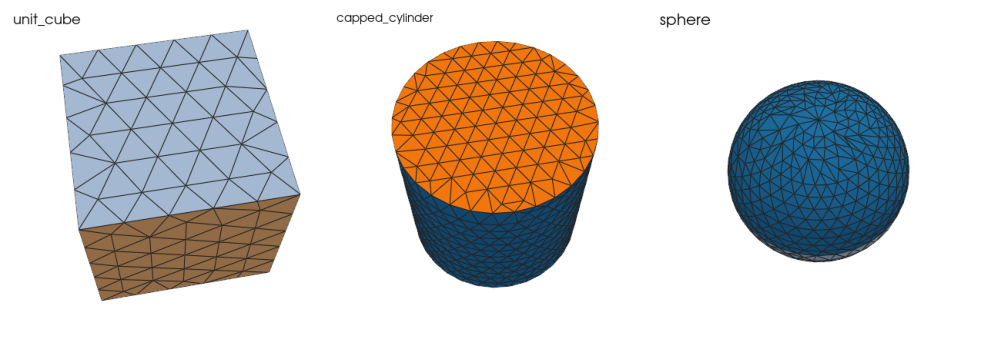

In [2]:
solids = {name: mp.read(CAD / f'{name}.cad.json') for name in ('unit_cube', 'capped_cylinder', 'sphere')}
surfaces = {}
for name, model in solids.items():
    surfaces[name], rep = mp.mesh_cad_surface(model, 0.2, return_report=True)
    print(f'{name}:')
    show_report(rep, ['num_faces', 'num_failed', 'num_points', 'num_triangles', 'num_open_edges',
                      'num_non_manifold_edges', 'num_misoriented_edges', 'min_angle_deg', 'max_edge'])
render(list(surfaces.values()), list(surfaces), 'mesh_cad_solids')

Area and enclosed volume converge at second order as `h` halves: the points lie on the exact surfaces (each sphere point at radius 1 to rounding), and the error is the chordal error of flat triangles.

In [3]:
exact = {'capped_cylinder': (6 * np.pi, 2 * np.pi), 'sphere': (4 * np.pi, 4 * np.pi / 3)}
for name, (area, volume) in exact.items():
    previous = None
    for h in (0.4, 0.2, 0.1, 0.05):
        out = mp.mesh_cad_surface(solids[name], h)
        a, v = measure(out)
        err = abs(a - area) / area
        rate = '' if previous is None else f'  ratio {previous / err:.2f}'
        print(f'{name:16s} h={h:<5} triangles {len(triangles(out)):6d}  area error {err:.2e}  '
              f'volume error {abs(v - volume) / volume:.2e}{rate}')
        previous = err
r = np.linalg.norm(mp.mesh_cad_surface(solids['sphere'], 0.1).points, axis=1)
print(f'sphere points: radius within {np.abs(r - 1).max():.1e} of 1')

capped_cylinder  h=0.4   triangles    292  area error 1.18e-02  volume error 2.00e-02
capped_cylinder  h=0.2   triangles   1196  area error 2.89e-03  volume error 4.69e-03  ratio 4.08
capped_cylinder  h=0.1   triangles   4748  area error 7.41e-04  volume error 1.16e-03  ratio 3.91
capped_cylinder  h=0.05  triangles  19034  area error 1.85e-04  volume error 2.86e-04  ratio 4.01
sphere           h=0.4   triangles    316  area error 2.09e-02  volume error 4.00e-02
sphere           h=0.2   triangles   1342  area error 4.76e-03  volume error 9.37e-03  ratio 4.39
sphere           h=0.1   triangles   5446  area error 1.12e-03  volume error 2.31e-03  ratio 4.26
sphere           h=0.05  triangles  22202  area error 2.52e-04  volume error 5.67e-04  ratio 4.44
sphere points: radius within 4.4e-16 of 1


## Trimmed faces follow their trims

The plate with a hole is one bilinear patch trimmed by an outer square and a circular hole. A CAD JSON read samples the patch on a lattice and keeps the cells whose centre is inside the trims, so its trimmed edges are staircases (left). `mesh_cad_surface` triangulates the trimmed domain itself, so the hole is a polygon inscribed in the circle (right), and `max_chordal_deviation` (OpenCASCADE's linear deflection) bounds how far its segments sit from the curve.

num_triangles            138
num_edge_segments        64
min_angle_deg            15.45
max_angle_deg            117.6
min_edge                 0.196
max_edge                 0.7406


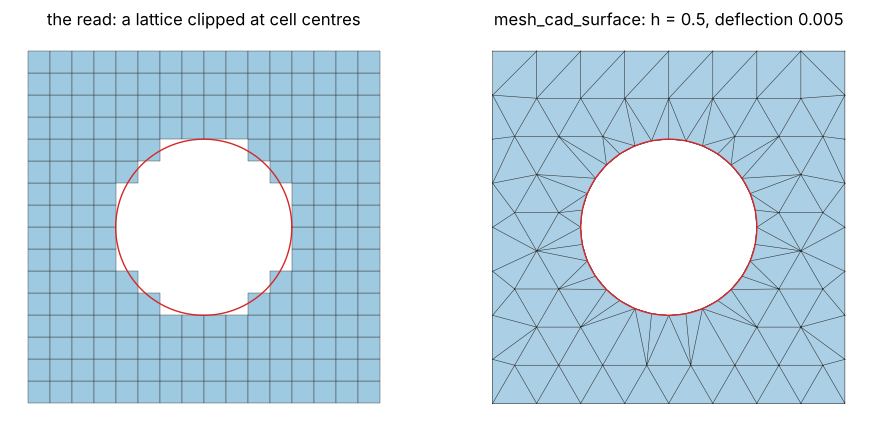

In [4]:
plate = mp.read(CAD / 'plate_with_hole.cad.json')
fine, rep = mp.mesh_cad_surface(plate, 0.5, max_chordal_deviation=0.005, return_report=True)
show_report(rep, ['num_triangles', 'num_edge_segments', 'min_angle_deg', 'max_angle_deg', 'min_edge', 'max_edge'])

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
sampled = [c for c in plate.cells if c.type.startswith('quad')]
p = np.asarray(plate.points)
for block in sampled:
    for cell in np.asarray(block.data)[:, :4]:  # quad9: the corners
        q = p[np.r_[cell, cell[0]]]
        axes[0].fill(q[:, 0], q[:, 1], facecolor='#9ecae1', edgecolor='#333333', linewidth=0.3)
axes[0].set_title('the read: a lattice clipped at cell centres')
q = np.asarray(fine.points)
axes[1].tripcolor(q[:, 0], q[:, 1], triangles(fine), facecolors=np.ones(len(triangles(fine))),
                  cmap='Blues', vmin=0, vmax=3, edgecolors='none')
axes[1].triplot(q[:, 0], q[:, 1], triangles(fine), color='#333333', linewidth=0.4)
axes[1].set_title('mesh_cad_surface: h = 0.5, deflection 0.005')
t = np.linspace(0, 2 * np.pi, 400)
for ax in axes:
    ax.plot(2 + np.cos(t), 2 + np.sin(t), color='#d62728', linewidth=1.0)  # the hole
    ax.set_aspect('equal'); ax.set_axis_off()
save_img('mesh_cad_plate')
plt.show()

## Stretched parameters: the Scordelis–Lo roof

The roof is one untrimmed rational patch, an 80° arc of a cylinder of radius 25 by 50 long, whose parameter scales differ about fortyfold. A Delaunay triangulation in raw `(u, v)` would be fortyfold stretched on the surface. Each face is therefore triangulated after one affine map, the Cholesky factor of its mean first fundamental form, so the triangles are near-equilateral on the surface and the area converges to the exact `25 · 80° · 50`.

h=4.0  triangles   274  min angle  26.0  edges 2.09 to 5.51  area error 1.330
h=2.0  triangles  1088  min angle  28.9  edges 1.03 to 2.73  area error 0.327
h=1.0  triangles  4402  min angle  27.7  edges 0.50 to 1.43  area error 0.081


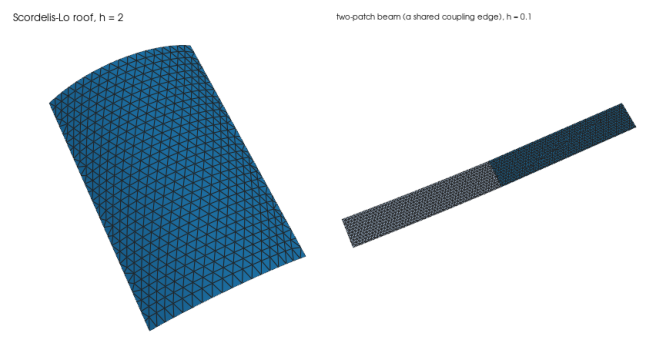

In [5]:
roof = mp.read(CAD / 'cylindrical_roof.cad.json')
exact_roof = 25.0 * np.radians(80.0) * 50.0
for h in (4.0, 2.0, 1.0):
    out, rep = mp.mesh_cad_surface(roof, h, return_report=True)
    print(f'h={h:<4} triangles {rep["num_triangles"]:5d}  min angle {rep["min_angle_deg"]:5.1f}  '
          f'edges {rep["min_edge"]:.2f} to {rep["max_edge"]:.2f}  area error {abs(measure(out)[0] - exact_roof):.3f}')
beam = mp.read(CAD / 'two_patch_beam.cad.json')
render([mp.mesh_cad_surface(roof, 2.0), mp.mesh_cad_surface(beam, 0.1)],
       ['Scordelis-Lo roof, h = 2', 'two-patch beam (a shared coupling edge), h = 0.1'],
       'mesh_cad_roof', view=(35, 20))

## Embedded edges, closed edges started elsewhere, crossings at a coarse size

Since v17.14.0 three inputs the first milestone reported are meshed:

- **Embedded edges.** The two-patch beam's first face carries an embedded edge, a line across it that no loop bounds (a coupling or load curve). It is sampled like any edge and constrained into the face's triangulation after the loops are classified, so it never changes what is inside; the mesh carries it as edges (red, left).
- **Coarse crossings.** A plate with a hole whose edge comes within 0.02 of the rim, meshed at `h = 1.1`: a coarse rim chord passes inside the hole's sample, so the sampled loops cross. Every piece involved is halved by arc length, in every face that uses its edge, until they do not (the boundary points near the gap, right).
- **Closed edges started elsewhere.** A capped cylinder whose top cap's circle starts a quarter turn after the band's rim: the cap is a loop of its own, so it is rotated onto the rim's corner and the solid closes.

beam: faces failed 0 - embedded segments 16 - warnings 0
plate with a near hole at h = 1.1: faces failed 0 - points 26 - area 9.1486 of 9.4248


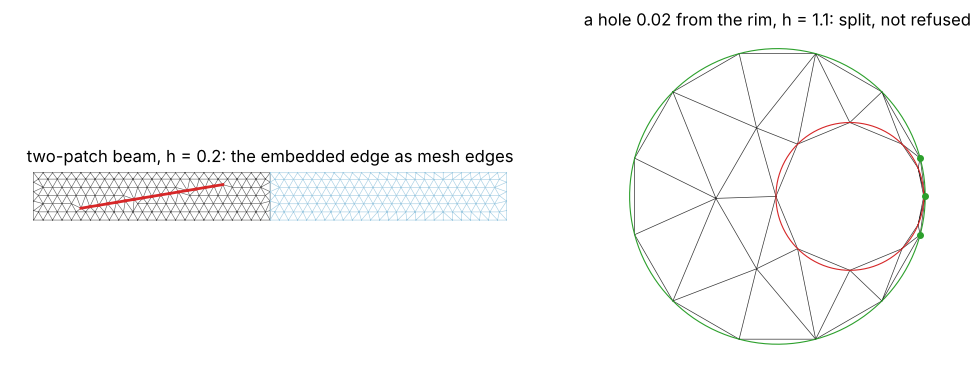

capped cylinder, cap started a quarter turn later: faces failed 0 - open edges 0 - volume 6.2537 of 6.2832


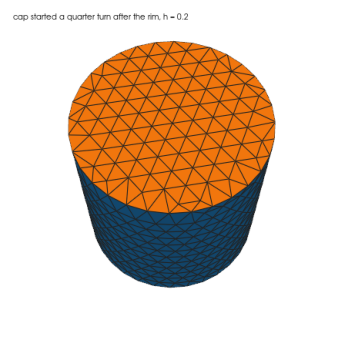

In [6]:
def interior_lines(mesh, face=0):
    """Line cells that are edges of two triangles of one face: an embedded curve."""
    t = triangles(mesh)[np.asarray(mesh.cell_data['cad:face'][0]) == face]
    uses = {}
    for a, b in np.r_[t[:, [0, 1]], t[:, [1, 2]], t[:, [2, 0]]]:
        key = (min(a, b), max(a, b))
        uses[key] = uses.get(key, 0) + 1
    lines = np.asarray([c for c in mesh.cells if c.type == 'line'][0].data)
    return np.array([l for l in lines if uses.get((min(l), max(l)), 0) == 2])


beam_mesh, rep = mp.mesh_cad_surface(beam, 0.2, return_report=True)
emb = interior_lines(beam_mesh)
print('beam: faces failed', rep['num_failed'], '- embedded segments', len(emb),
      '- warnings', len(rep['warnings']))

near = mp.read(CAD / 'plate_with_near_hole.cad.json')
coarse, rep = mp.mesh_cad_surface(near, 1.1, return_report=True)
print('plate with a near hole at h = 1.1: faces failed', rep['num_failed'],
      '- points', rep['num_points'], '- area %.4f of %.4f' % (measure(coarse)[0], 3 * np.pi))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={'width_ratios': [1.6, 1]})
p, t = np.asarray(beam_mesh.points), triangles(beam_mesh)
on0 = np.asarray(beam_mesh.cell_data['cad:face'][0]) == 0
axes[0].triplot(p[:, 0], p[:, 1], t[on0], color='#555555', linewidth=0.4)
axes[0].triplot(p[:, 0], p[:, 1], t[~on0], color='#9ecae1', linewidth=0.4)
for a, b in emb:
    axes[0].plot(p[[a, b], 0], p[[a, b], 1], color='#d62728', linewidth=2.0)
axes[0].set_title('two-patch beam, h = 0.2: the embedded edge as mesh edges')
q, s = np.asarray(coarse.points), triangles(coarse)
axes[1].triplot(q[:, 0], q[:, 1], s, color='#333333', linewidth=0.5)
a = np.linspace(0, 2 * np.pi, 400)
axes[1].plot(2 * np.cos(a), 2 * np.sin(a), color='#2ca02c', linewidth=0.8)
axes[1].plot(0.98 + np.cos(a), np.sin(a), color='#d62728', linewidth=0.8)
rim = np.isclose(np.hypot(q[:, 0], q[:, 1]), 2.0) & (q[:, 0] > 1.5)
axes[1].plot(q[rim, 0], q[rim, 1], 'o', color='#2ca02c', markersize=4)
axes[1].set_title('a hole 0.02 from the rim, h = 1.1: split, not refused')
for ax in axes:
    ax.set_aspect('equal'); ax.set_axis_off()
save_img('mesh_cad_crossings')
plt.show()

offset = mp.read(CAD / 'capped_cylinder_offset.cad.json')
out, rep = mp.mesh_cad_surface(offset, 0.2, return_report=True)
print('capped cylinder, cap started a quarter turn later: faces failed', rep['num_failed'],
      '- open edges', rep['num_open_edges'], '- volume %.4f of %.4f' % (measure(out)[1], 2 * np.pi))
render([out], ['cap started a quarter turn after the rim, h = 0.2'], 'mesh_cad_offset_cylinder')

## Quality: refinement to a minimum angle

Since v17.15.0 `min_angle` refines every face by Delaunay refinement (Ruppert's algorithm with Chew's circumcentres) until its triangles' smallest angles, **measured on the surface**, reach the bound. A boundary piece a new point would encroach is split instead, by arc length and in every face that uses its edge, so the faces still meet exactly. Bad triangles are taken worst first, ties broken by their sorted vertex ids, so the mesh is the same on every run, backend and thread count. With `min_angle=0` (the default) the mesh is the unrefined one byte for byte.

The bound is guaranteed to 20.7 degrees on a plane away from corners under 60 degrees; above it, as here at 25, it is a target whose shortfall is reported. Two things keep triangles below it, and both are reported per face in `corners`: a corner where two trims meet at under 60 degrees, and a pole (the sphere's two, left to graded poles, roadmap 6.4.2). Every angle of every triangle goes into `angle_histogram`, 18 bins of 10 degrees.

trimmed plate    h = 0.5, min_angle =  0: points    85, refinement points    0, smallest angle 23.79, away from corners 23.79, corners reported 0
trimmed plate    h = 0.5, min_angle = 25: points    87, refinement points    2, smallest angle 25.21, away from corners 25.21, corners reported 0

capped cylinder  h = 0.2, min_angle =  0: points   600, refinement points    0, smallest angle 25.25, away from corners 25.25, corners reported 0
capped cylinder  h = 0.2, min_angle = 25: points   626, refinement points   44, smallest angle 26.62, away from corners 26.62, corners reported 0

sphere           h = 0.2, min_angle =  0: points   673, refinement points    0, smallest angle 10.16, away from corners 20.86, corners reported 0
sphere           h = 0.2, min_angle = 25: points   677, refinement points    8, smallest angle 10.16, away from corners 26.14, corners reported 2 (2 poles)



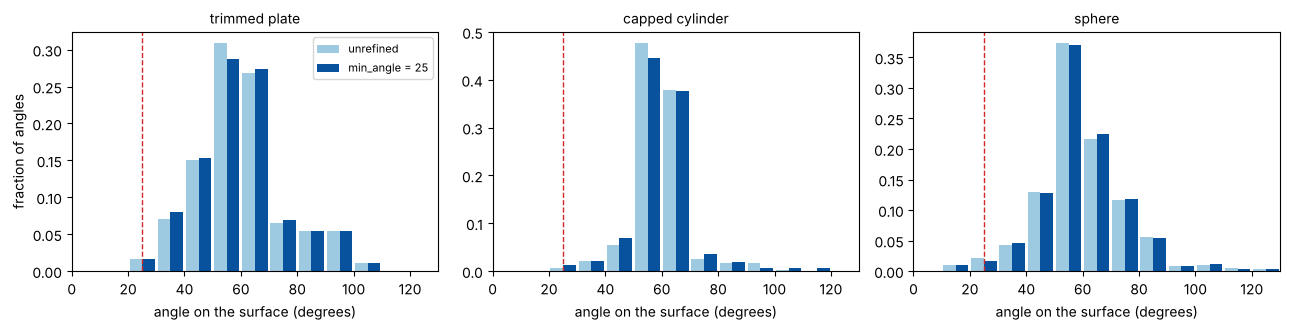

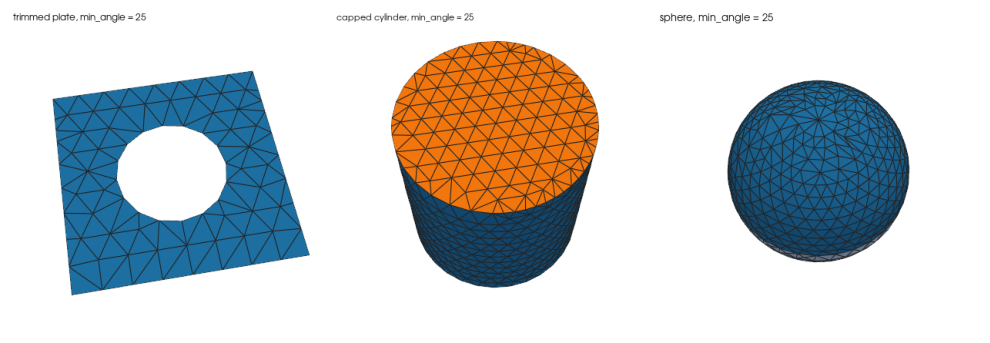

In [7]:
models = {'trimmed plate': (mp.read(CAD / 'plate_with_hole.cad.json'), 0.5),
          'capped cylinder': (solids['capped_cylinder'], 0.2),
          'sphere': (solids['sphere'], 0.2)}
refined, histograms = {}, {}
for name, (model, h) in models.items():
    for angle in (0, 25):
        out, rep = mp.mesh_cad_surface(model, h, min_angle=angle, return_report=True)
        histograms[name, angle] = np.asarray(rep['angle_histogram'])
        corners = [c for f in rep['faces'] for c in f['corners']]
        bound = min(f['bound_deg'] for f in rep['faces'])
        print(f'{name:16s} h = {h}, min_angle = {angle:2d}: points {rep["num_points"]:5d}, '
              f'refinement points {rep["num_refinement_points"]:4d}, smallest angle {rep["min_angle_deg"]:5.2f}, '
              f'away from corners {bound:5.2f}, corners reported {len(corners)}'
              + (f' ({sum(c["pole"] for c in corners)} poles)' if corners else ''))
        if angle:
            refined[name] = out
    print()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=False)
edges = np.arange(0, 181, 10)
for ax, name in zip(axes, models):
    for angle, colour in ((0, '#9ecae1'), (25, '#08519c')):
        hist = histograms[name, angle]
        ax.bar(edges[:-1] + (5 if angle else 0.5), hist / hist.sum(), width=4.5, align='edge',
               color=colour, label='unrefined' if not angle else 'min_angle = 25')
    ax.axvline(25, color='#d62728', linewidth=1, linestyle='--')
    ax.set_xlim(0, 130); ax.set_title(name, fontsize=10); ax.set_xlabel('angle on the surface (degrees)')
axes[0].set_ylabel('fraction of angles'); axes[0].legend(fontsize=8)
plt.tight_layout()
save_img('mesh_cad_quality_histogram')
plt.show()
render(list(refined.values()), [f'{n}, min_angle = 25' for n in refined], 'mesh_cad_refined')

On the sphere the triangles left under the bound are those at its poles, which a fan apex forces. The report names each pole with its reach, the distance within which refinement leaves the triangles to graded poles:

In [8]:
_, rep = mp.mesh_cad_surface(solids['sphere'], 0.2, min_angle=25, return_report=True)
for k, f in enumerate(rep['faces']):
    for c in f['corners']:
        print(f'face {k}: pole {c["pole"]}, at z = {c["x"][2]:+.3f}, reach {c["reach"]:.3f}, '
              f'smallest angle it forces {c["min_forced_deg"]:.2f}')
    print(f'face {k}: below bound {f["below_bound"]}, smallest angle away from its corners {f["bound_deg"]:.2f}')

face 0: pole True, at z = +1.000, reach 0.375, smallest angle it forces 14.53
face 0: below bound True, smallest angle away from its corners 26.65
face 1: pole True, at z = -1.000, reach 0.375, smallest angle it forces 10.16
face 1: below bound True, smallest angle away from its corners 26.14


## Guarded smoothing

`smooth_iterations` moves every interior point toward the centroid of its neighbours (`laplacian`) or its star's area-weighted circumcentre (`odt`), in the face's plane, lifted onto the surface. A move is kept only when no triangle of its star inverts and the star's smallest angle on the surface does not drop, and Lawson flips follow each pass. Boundary points never move, so the faces still share their edges.

In [9]:
near = mp.read(CAD / 'plate_with_near_hole.cad.json')
for kw in ({}, {'smooth_iterations': 3}, {'smooth_iterations': 3, 'smooth_method': 'odt'},
           {'min_angle': 25, 'smooth_iterations': 3}):
    _, rep = mp.mesh_cad_surface(near, 0.3, return_report=True, **kw)
    hist = np.asarray(rep['angle_histogram'])
    print(f'{str(kw):55s} smallest {rep["min_angle_deg"]:5.2f}, moved {rep["num_smoothed"]:4d}, '
          f'angles under 30: {hist[:3].sum() / hist.sum():.2%}')

{}                                                      smallest  5.96, moved    0, angles under 30: 2.60%
{'smooth_iterations': 3}                                smallest  5.96, moved  204, angles under 30: 2.21%
{'smooth_iterations': 3, 'smooth_method': 'odt'}        smallest  5.96, moved  189, angles under 30: 1.95%
{'min_angle': 25, 'smooth_iterations': 3}               smallest 26.39, moved  195, angles under 30: 0.46%


## Measured by what a mesh is for: interpolation error

Angles say a mesh is valid; the interpolation error says it is good for a field (Shewchuk 2002). The linear interpolant of a smooth field on the sphere's mesh is compared with the field at the 7-point degree-5 rule of Dunavant on each triangle, projected onto the sphere, as `h` halves. The observed orders are 2 with and without refinement; the C++ test `MeshCadInterpolation` pins them on the sphere and the Scordelis–Lo roof.

In [10]:
# Dunavant's 7-point rule (degree 5): barycentric points and weights.
a1, b1 = 0.059715871789770, 0.470142064105115
a2, b2 = 0.797426985353087, 0.101286507323456
bary = np.array([[1 / 3, 1 / 3, 1 / 3], [a1, b1, b1], [b1, a1, b1], [b1, b1, a1],
                 [a2, b2, b2], [b2, a2, b2], [b2, b2, a2]])
weights = np.array([0.225] + [0.132394152788506] * 3 + [0.125939180544827] * 3)


def field(x):
    return np.sin(2 * x[..., 0]) * np.cos(1.5 * x[..., 1]) + np.exp(x[..., 2] / 2)


def interpolation_error(mesh):
    p, t = np.asarray(mesh.points), triangles(mesh)
    corners = p[t]                                          # (n, 3, 3)
    area = 0.5 * np.linalg.norm(np.cross(corners[:, 1] - corners[:, 0], corners[:, 2] - corners[:, 0]), axis=1)
    q = np.einsum('qk,nkd->nqd', bary, corners)            # quadrature points on the flat triangles
    on_sphere = q / np.linalg.norm(q, axis=2, keepdims=True)
    interpolated = np.einsum('qk,nk->nq', bary, field(p)[t])
    e = interpolated - field(on_sphere)
    return np.sqrt((area[:, None] * weights * e**2).sum()), np.abs(e).max()


for angle in (0, 25):
    previous = None
    for h in (0.2, 0.1, 0.05):
        out = mp.mesh_cad_surface(solids['sphere'], h, min_angle=angle)
        l2, emax = interpolation_error(out)
        order = '' if previous is None else f'   L2 order {np.log2(previous / l2):.2f}'
        print(f'min_angle = {angle:2d}, h = {h:<5}: L2 error {l2:.3e}, max error {emax:.3e}{order}')
        previous = l2

min_angle =  0, h = 0.2  : L2 error 1.655e-02, max error 3.408e-02
min_angle =  0, h = 0.1  : L2 error 3.979e-03, max error 7.329e-03   L2 order 2.06
min_angle =  0, h = 0.05 : L2 error 9.899e-04, max error 5.050e-03   L2 order 2.01
min_angle = 25, h = 0.2  : L2 error 1.594e-02, max error 3.034e-02


min_angle = 25, h = 0.1  : L2 error 3.671e-03, max error 7.329e-03   L2 order 2.12


min_angle = 25, h = 0.05 : L2 error 9.043e-04, max error 5.050e-03   L2 order 2.02


## Curved elements: `order` 2 and 3

Since v17.16.0 `order=2` writes quadratic `triangle6` elements and `order=3` cubic `triangle10` ones (with `line3` and `line4` edges). The corners are the linear mesh's points; a node on an edge inside a face is the surface at a parameter fraction of the edge's corners, a node on a B-rep edge is the edge at an arc-length fraction of its piece (shared by both faces, so the mesh stays conforming), and a cubic element's face node is the surface at its parameter centroid. Every element's area element `J = (x_ξ × x_η) · N` against its face's normal is expanded in Bernstein form and proved positive everywhere inside, or the element is kept straight-sided and counted (Johnen, Remacle and Geuzaine 2013).

The coarse sphere below is drawn by subdividing each element through its own Lagrange map; the dark lines are the elements' edges, curved on the sphere for orders 2 and 3.

order 1: ['triangle', 'line'], 67 points, 0 kept straight-sided
order 2: ['triangle6', 'line3'], 264 points, 0 kept straight-sided
order 3: ['triangle10', 'line4'], 591 points, 0 kept straight-sided
every cubic node within 3.3e-16 of the unit sphere


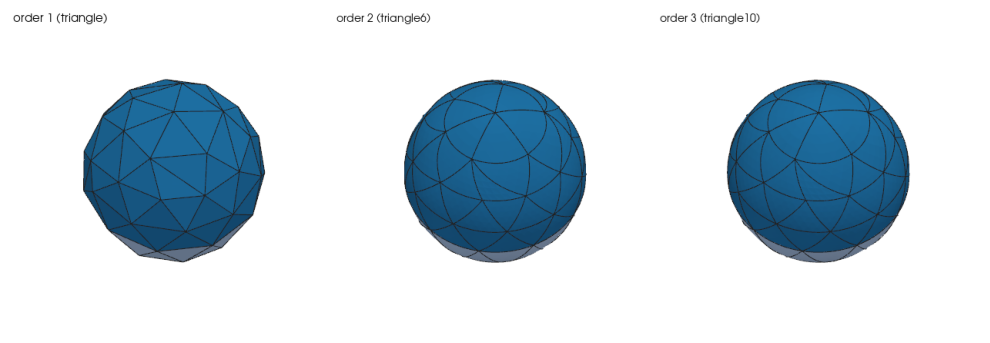

In [11]:
# Reference nodes in the Gmsh/meshio layout of each order: corners, then each
# edge's nodes from its first corner, then (cubic) the centre.
REF = {1: [(0, 0), (1, 0), (0, 1)],
       2: [(0, 0), (1, 0), (0, 1), (.5, 0), (.5, .5), (0, .5)],
       3: [(0, 0), (1, 0), (0, 1), (1 / 3, 0), (2 / 3, 0), (2 / 3, 1 / 3), (1 / 3, 2 / 3),
           (0, 2 / 3), (0, 1 / 3), (1 / 3, 1 / 3)]}
TYPE = {1: 'triangle', 2: 'triangle6', 3: 'triangle10'}


def monomials(order, xi, eta):
    """x^i y^j, i + j <= order, at the points (xi, eta), with both derivatives."""
    pw = [(i, j) for i in range(order + 1) for j in range(order + 1 - i)]
    xi, eta = np.asarray(xi, float), np.asarray(eta, float)
    v = np.stack([xi**i * eta**j for i, j in pw], -1)
    dx = np.stack([i * xi**max(i - 1, 0) * eta**j for i, j in pw], -1)
    dy = np.stack([j * xi**i * eta**max(j - 1, 0) for i, j in pw], -1)
    return v, dx, dy


def shape(order, xi, eta):
    """The Lagrange shape functions and their derivatives at (xi, eta)."""
    r = np.asarray(REF[order])
    inv = np.linalg.inv(monomials(order, r[:, 0], r[:, 1])[0])
    return tuple(m @ inv for m in monomials(order, xi, eta))


def elements(mesh, order):
    block = [c for c in mesh.cells if c.type == TYPE[order]][0]
    return np.asarray(mesh.points)[np.asarray(block.data)]   # (n, nodes, 3)


def subdivided(mesh, order, k=6):
    """Each element as k^2 flat triangles through its own map, its edges as polylines."""
    nodes = elements(mesh, order)
    lattice = [(i / k, j / k) for i in range(k + 1) for j in range(k + 1 - i)]
    index = {ij: n for n, ij in enumerate((i, j) for i in range(k + 1) for j in range(k + 1 - i))}
    tri = []
    for i in range(k):
        for j in range(k - i):
            tri.append((index[i, j], index[i + 1, j], index[i, j + 1]))
            if i + j < k - 1:
                tri.append((index[i + 1, j], index[i + 1, j + 1], index[i, j + 1]))
    N = shape(order, *np.asarray(lattice).T)[0]                # (lattice, nodes)
    pts = np.einsum('ln,end->eld', N, nodes)                   # (elements, lattice, 3)
    s = np.linspace(0, 1, 4 * order + 1)
    sides = [(s, 0 * s), (1 - s, s), (0 * s, 1 - s)]
    lines = [np.einsum('ln,end->eld', shape(order, a, b)[0], nodes) for a, b in sides]
    tris = (np.asarray(tri)[None] + len(lattice) * np.arange(len(nodes))[:, None, None]).reshape(-1, 3)
    face = np.repeat(np.asarray(mesh.cell_data['cad:face'][0]), len(tri))
    return pts.reshape(-1, 3), tris, face, np.concatenate(lines)


def render_curved(meshes, orders, titles, save, view=(20, 30)):
    n = len(meshes)
    parts = [subdivided(m, o) for m, o in zip(meshes, orders)]
    # Lift the edges 0.5% off the surface (about its centre) so the facets do
    # not hide them: these solids are convex about their centre.
    parts = [(p, t, face, p.mean(axis=0) + 1.005 * (lines - p.mean(axis=0))) for p, t, face, lines in parts]
    if GL:
        pl = pv.Plotter(off_screen=True, shape=(1, n), window_size=(420 * n, 420), border=False)
        for k, ((p, t, face, lines), title) in enumerate(zip(parts, titles)):
            pl.subplot(0, k)
            surf = pv.PolyData(p, np.hstack([np.full((len(t), 1), 3), t]).ravel())
            surf.cell_data['cad:face'] = face
            pl.add_mesh(surf, scalars='cad:face', cmap='tab20', clim=(0, 19), show_scalar_bar=False,
                        ambient=0.35, diffuse=0.65)
            m = lines.shape[1]
            segments = np.arange(len(lines))[:, None] * m + np.arange(m - 1)[None, :]
            cells = np.c_[np.full(segments.size, 2), segments.ravel(), segments.ravel() + 1]
            pl.add_mesh(pv.PolyData(lines.reshape(-1, 3), lines=cells.ravel()), color='#222222',
                        line_width=1.2)
            pl.add_text(title, font_size=9)
            pl.camera.elevation, pl.camera.azimuth = view
            pl.reset_camera()
        img = pl.screenshot(return_img=True)
        pl.close()
        save_img(save, img)
        plt.figure(figsize=(4.2 * n, 4.2)); plt.imshow(img); plt.axis('off'); plt.show()
        return
    from mpl_toolkits.mplot3d.art3d import Line3DCollection
    fig = plt.figure(figsize=(4.2 * n, 4.2))
    elev, azim = np.radians(view)
    eye = np.array([np.cos(elev) * np.cos(azim), np.cos(elev) * np.sin(azim), np.sin(elev)])
    for k, ((p, t, face, lines), title) in enumerate(zip(parts, titles)):
        ax = fig.add_subplot(1, n, k + 1, projection='3d')
        ax.computed_zorder = False  # the edges over the surface, not sorted behind it
        colours = plt.get_cmap('tab20')((face % 20) / 19.0)
        ax.add_collection3d(Poly3DCollection(p[t], facecolors=colours, edgecolors='none', zorder=1))
        # Only the edges on the near side (these solids are convex about their centre).
        front = (lines.mean(axis=1) - p.mean(axis=0)) @ eye > 0
        ax.add_collection3d(Line3DCollection(lines[front], colors='#222222', linewidths=0.6, zorder=2))
        lo, hi = p.min(axis=0), p.max(axis=0)
        ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
        ax.set_box_aspect(hi - lo + 1e-9); ax.view_init(elev=view[0], azim=view[1])
        ax.set_axis_off(); ax.set_title(title, fontsize=9)
    save_img(save)
    plt.show()


coarse = {}
for order in (1, 2, 3):
    coarse[order], rep = mp.mesh_cad_surface(solids['sphere'], 0.6, order=order, return_report=True)
    print(f'order {order}: {[c.type for c in coarse[order].cells]}, {len(coarse[order].points)} points, '
          f'{rep["num_curved_straightened"]} kept straight-sided')
r = np.linalg.norm(coarse[3].points, axis=1)
print(f'every cubic node within {np.abs(r - 1).max():.1e} of the unit sphere')
render_curved([coarse[o] for o in (1, 2, 3)], (1, 2, 3),
              ['order 1 (triangle)', 'order 2 (triangle6)', 'order 3 (triangle10)'], 'mesh_cad_curved')

Area and enclosed volume, integrated over the curved elements by a collapsed 8 × 8 Gauss–Legendre rule, converge at order 2 for flat triangles and about 4 for both curved orders; the cubic errors are several times smaller than the quadratic ones. The cubic order stays near 4 rather than 6 because the interior nodes sit at parameter fractions (roadmap 6.6.2). The interpolation error of a smooth field, the curved element's own Lagrange interpolant against the field, converges over the whole sphere at about 2, 2.5 and 3.4: the poles' fans hold the curved elements back (graded poles, roadmap 6.4.2), and away from them the orders are 2, 3 and 3.7. The C++ tests `MeshCadCurved` and `MeshCadInterpolation` pin both.

In [12]:
gx, gw = np.polynomial.legendre.leggauss(8)
gx, gw = (gx + 1) / 2, gw / 2
U, V = np.meshgrid(gx, gx, indexing='ij')
QXI, QETA = U.ravel(), (V * (1 - U)).ravel()                       # collapsed onto the triangle
QW = (np.outer(gw, gw) * (1 - U)).ravel()


def curved_measure(mesh, order, f=None):
    """Area, enclosed volume and (with f) the L2 interpolation error of the curved elements."""
    nodes = elements(mesh, order)
    N, Nx, Ny = shape(order, QXI, QETA)
    x = np.einsum('qn,end->eqd', N, nodes)
    n = np.cross(np.einsum('qn,end->eqd', Nx, nodes), np.einsum('qn,end->eqd', Ny, nodes))
    da = np.linalg.norm(n, axis=2)
    area = (QW * da).sum()
    volume = (QW * np.einsum('eqd,eqd->eq', x, n)).sum() / 3.0
    if f is None:
        return area, volume
    e = f(x) - np.einsum('qn,en->eq', N, f(nodes))
    return area, volume, np.sqrt((QW * da * e**2).sum())


exact = {'capped_cylinder': (6 * np.pi, 2 * np.pi), 'sphere': (4 * np.pi, 4 * np.pi / 3)}
for name, (area, volume) in exact.items():
    for order in (1, 2, 3):
        previous = None
        for h in (0.4, 0.2, 0.1):
            out = mp.mesh_cad_surface(solids[name], h, order=order)
            a, v = curved_measure(out, order)
            ea, ev = abs(a - area) / area, abs(v - volume) / volume
            rates = '' if previous is None else f'  orders {np.log2(previous[0] / ea):.2f} {np.log2(previous[1] / ev):.2f}'
            print(f'{name:16s} order {order}  h={h:<4}  area error {ea:.2e}  volume error {ev:.2e}{rates}')
            previous = (ea, ev)
for order in (1, 2, 3):
    previous = None
    for h in (0.2, 0.1, 0.05):
        l2 = curved_measure(mp.mesh_cad_surface(solids['sphere'], h, order=order), order, field)[2]
        rate = '' if previous is None else f'   L2 order {np.log2(previous / l2):.2f}'
        print(f'sphere interpolation, order {order}, h = {h:<5}: L2 error {l2:.3e}{rate}')
        previous = l2

capped_cylinder  order 1  h=0.4   area error 1.18e-02  volume error 2.00e-02
capped_cylinder  order 1  h=0.2   area error 2.89e-03  volume error 4.69e-03  orders 2.03 2.09
capped_cylinder  order 1  h=0.1   area error 7.41e-04  volume error 1.16e-03  orders 1.97 2.01
capped_cylinder  order 2  h=0.4   area error 2.83e-05  volume error 4.31e-05
capped_cylinder  order 2  h=0.2   area error 1.70e-06  volume error 2.42e-06  orders 4.06 4.16


capped_cylinder  order 2  h=0.1   area error 1.06e-07  volume error 1.37e-07  orders 4.01 4.14
capped_cylinder  order 3  h=0.4   area error 5.17e-06  volume error 7.49e-06
capped_cylinder  order 3  h=0.2   area error 2.86e-07  volume error 3.79e-07  orders 4.17 4.30
capped_cylinder  order 3  h=0.1   area error 1.80e-08  volume error 2.27e-08  orders 3.99 4.06


sphere           order 1  h=0.4   area error 2.09e-02  volume error 4.00e-02
sphere           order 1  h=0.2   area error 4.76e-03  volume error 9.37e-03  orders 2.13 2.09
sphere           order 1  h=0.1   area error 1.12e-03  volume error 2.31e-03  orders 2.09 2.02
sphere           order 2  h=0.4   area error 2.37e-04  volume error 4.13e-04
sphere           order 2  h=0.2   area error 1.23e-05  volume error 2.16e-05  orders 4.26 4.26


sphere           order 2  h=0.1   area error 8.09e-07  volume error 1.44e-06  orders 3.93 3.90
sphere           order 3  h=0.4   area error 1.44e-05  volume error 1.82e-05
sphere           order 3  h=0.2   area error 7.49e-07  volume error 1.03e-06  orders 4.26 4.15


sphere           order 3  h=0.1   area error 4.55e-08  volume error 6.33e-08  orders 4.04 4.02
sphere interpolation, order 1, h = 0.2  : L2 error 1.537e-02
sphere interpolation, order 1, h = 0.1  : L2 error 3.756e-03   L2 order 2.03


sphere interpolation, order 1, h = 0.05 : L2 error 9.259e-04   L2 order 2.02
sphere interpolation, order 2, h = 0.2  : L2 error 4.640e-04


sphere interpolation, order 2, h = 0.1  : L2 error 6.850e-05   L2 order 2.76


sphere interpolation, order 2, h = 0.05 : L2 error 1.193e-05   L2 order 2.52
sphere interpolation, order 3, h = 0.2  : L2 error 2.854e-05


sphere interpolation, order 3, h = 0.1  : L2 error 2.116e-06   L2 order 3.75


sphere interpolation, order 3, h = 0.05 : L2 error 2.021e-07   L2 order 3.39


An element the curved boundary would fold is not written tangled. At `h = 1.75` the capped cylinder holds a few large triangles, and some cubic elements' Jacobians are not positive everywhere against their face's normal: they are made straight-sided, counted and warned, and every element written is valid. At `h = 0.3` none folds.

In [13]:
for h in (1.75, 0.3):
    _, rep = mp.mesh_cad_surface(solids['capped_cylinder'], h, order=3, return_report=True)
    print(f'h = {h}: {rep["num_triangles"]} elements, {rep["num_curved_straightened"]} kept straight-sided')
    for w in rep['warnings']:
        print('  warning:', w)

h = 1.75: 14 elements, 4 kept straight-sided
h = 0.3: 512 elements, 0 kept straight-sided


meshio warning [mesh_cad.cpp:1768] mesh_cad_surface: 4 curved elements had a Jacobian that is not positive everywhere and are kept straight-sided


## A face that fails is reported, not meshed wrong

Corrupt one face of the cube (its patch index points nowhere). The face is left out and recorded with its status and reason; the open-edge count shows the hole; the other faces are unchanged. `strict=True` raises instead.

In [14]:
import copy

brep = copy.deepcopy(solids['unit_cube'].info['brep'])
brep['faces'][2]['patch'] = 99
broken, rep = mp.mesh_cad_surface(brep, 0.25, return_report=True)
print('failed faces:', rep['num_failed'], '- open edges:', rep['num_open_edges'])
for f in rep['faces']:
    if f['status'] != 'ok':
        print(f"face {f['face']}: {f['status']}: {f['reason']}")
try:
    mp.mesh_cad_surface(brep, 0.25, strict=True)
except RuntimeError as exc:
    print('strict:', exc)

failed faces: 1 - open edges: 16
face 2: unsupported: its patch index is out of range
strict: meshio++: mesh_cad_surface: face 2 is not meshed (unsupported): its patch index is out of range


meshio warning [mesh_cad.cpp:1768] mesh_cad_surface: face 2 is not meshed (unsupported): its patch index is out of range
meshio warning [mesh_cad.cpp:1768] mesh_cad_surface: face 2 is not meshed (unsupported): its patch index is out of range


## The planar triangulator

`triangulate_polygon_2d` is the constrained Delaunay triangulation underneath: a polygon with holes in the plane z = 0, either orientation, the even-odd rule deciding inside. With `target_size=0` it keeps the boundary as given; with `h > 0` it splits the boundary and fills the inside with a lattice.

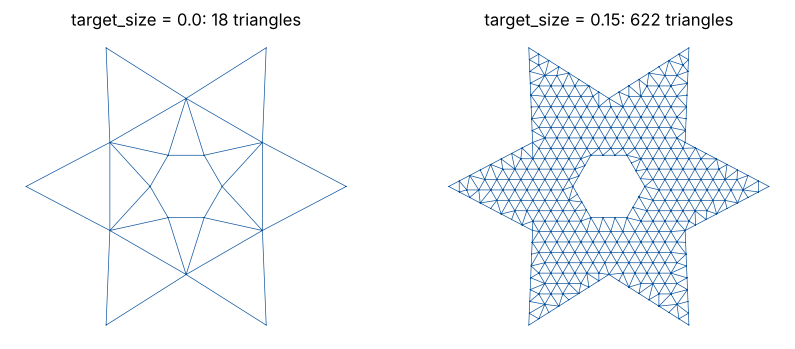

In [15]:
t = np.linspace(0, 2 * np.pi, 13)[:-1]
star = np.c_[np.cos(t), np.sin(t)] * np.where(np.arange(12) % 2, 0.55, 1.0)[:, None] * 2
hole = np.c_[0.45 * np.cos(-t[::2]), 0.45 * np.sin(-t[::2])]
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, h in zip(axes, (0.0, 0.15)):
    m = mp.triangulate_polygon_2d(star, [hole], target_size=h)
    q = np.asarray(m.points)
    ax.triplot(q[:, 0], q[:, 1], np.asarray(m.cells[0].data), color='#08519c', linewidth=0.5)
    ax.set_title(f'target_size = {h}: {len(m.cells[0].data)} triangles')
    ax.set_aspect('equal'); ax.set_axis_off()
save_img('mesh_cad_polygon')
plt.show()

## A STEP solid, with OpenCASCADE

Where OpenCASCADE is linked, a STEP or IGES read carries the same B-rep, so `mesh_cad_surface` meshes it at a target size where the read's own `BRepMesh` triangulation is driven by deflection. The two agree on the area and enclosed volume of a box exactly.

In [16]:
if getattr(mp._core, '__has_occt__', False):
    path = os.path.join(tempfile.mkdtemp(), 'box.step')
    mp.write(path, mp.extract_surface(mp.box()))
    model = mp.read(path)
    ours, rep = mp.mesh_cad_surface(model, 0.1, return_report=True)
    print('BRepMesh:         triangles %5d  area %.12f  volume %.12f' % ((len(triangles(model)),) + measure(model)))
    print('mesh_cad_surface: triangles %5d  area %.12f  volume %.12f' % ((len(triangles(ours)),) + measure(ours)))
    print('open edges:', rep['num_open_edges'])
else:
    print('this build has no OpenCASCADE: STEP and IGES are not read')

BRepMesh:         triangles    12  area 6.000000000000  volume 1.000000000000
mesh_cad_surface: triangles  1488  area 6.000000000000  volume 1.000000000000
open edges: 0
